In [36]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

# *Imports*

In [37]:
import os
import re
import random
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
import wandb
seed = 42
random.seed(seed)
np.random.seed(seed)
sns.set_style('whitegrid')
print('Library loaded')


Library loaded


In [38]:
import os
import wandb
from kaggle_secrets import UserSecretsClient

# Kaggle Secret se key lo — automatically milegi
secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)
print("✅ W&B login successful!")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


✅ W&B login successful!


# *Load Data*

In [39]:
train_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
print(train_df.shape)
print(test_df.shape)

(2000, 8)
(500, 7)


In [40]:
train_df.head(5)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


# *Null Check*

In [41]:
print(train_df.info())
print(f"Null Values :\n{train_df.isnull().sum()}")
print(train_df['answer'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB
None
Null Values :
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64
answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64


# *Answer Distribution*

Text(0.5, 1.0, 'Answer Distribution')

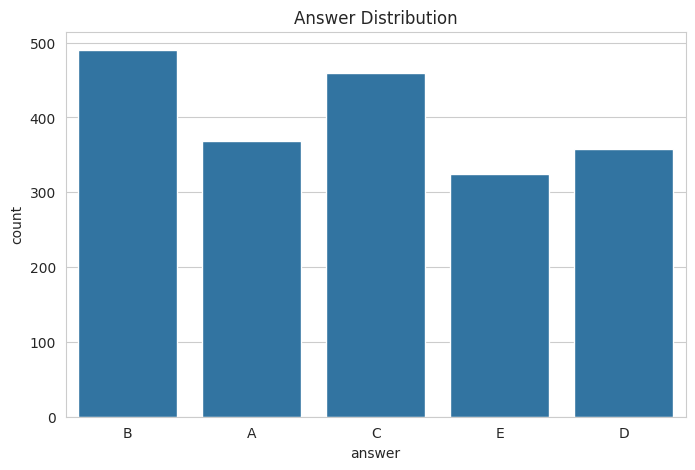

In [42]:
plt.figure(figsize=(8,5))
sns.countplot(x=train_df['answer'])
plt.title('Answer Distribution')

# *Text Cleaning*

In [43]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]','',text)
    text = re.sub(r'\s+',' ',text)
    return text.strip()

In [44]:
train_df['prompt'] = train_df['prompt'].apply(clean_text)
test_df['prompt'] = test_df['prompt'].apply(clean_text)
for col in ['A','B','C','D','E']:
    train_df[col] = train_df[col].apply(clean_text)
    test_df[col] = test_df[col].apply(clean_text)
print('Cleaning Text')

Cleaning Text


# *Convert Dataset for Classical ML*

In [45]:
# rows = []
# for _,row in train_df.iterrows():
#     for option in ['A','B','C','D','E']:
#         rows.append({
#              'text': row['prompt'] + '[SEP]' + row[option],
#              'label': 1 if option == row['answer'] else 0 ,
#              'question_id': row['id'],
#              'option': option
        
#         })
        
       
# ml_df = pd.DataFrame(rows)
# print('Expanded Shape:',ml_df.shape)
# ml_df.head(5)
        

In [46]:
rows = []

for _, row in train_df.iterrows():
    for option in ['A','B','C','D','E']:
        rows.append({
            'text': clean_text(
                f"Question: {row['prompt']} Answer: {row[option]}"
            ),
            'label': 1 if option == row['answer'] else 0,
            'question_id': row['id'],
            'option': option
        })

ml_df = pd.DataFrame(rows)

print(ml_df.head())

                                                text  label  question_id  \
0  questionpickthebestpossibleanswerwhatismartinh...      0            1   
1  questionpickthebestpossibleanswerwhatismartinh...      1            1   
2  questionpickthebestpossibleanswerwhatismartinh...      0            1   
3  questionpickthebestpossibleanswerwhatismartinh...      0            1   
4  questionpickthebestpossibleanswerwhatismartinh...      0            1   

  option  
0      A  
1      B  
2      C  
3      D  
4      E  


# *Train-Test Split*

In [47]:
train_data , val_data = train_test_split(
    ml_df , test_size = 0.2 , random_state = seed , stratify = ml_df['label']
)
print(train_data.shape)
print(val_data.shape)

(8000, 4)
(2000, 4)


# *Tfidf*

In [48]:
vectorizer = TfidfVectorizer(
    max_features = 60000,
    ngram_range = (1,2),
    stop_words = 'english',
    max_df = 0.95,
    min_df = 2,
    sublinear_tf = True
)
X_train = vectorizer.fit_transform(train_data['text'])
X_val = vectorizer.transform(val_data['text'])
y_train = train_data['label']
y_val = val_data['label']
print(X_train.shape)


(8000, 613)


# *Logistic Regression Model*

In [49]:
lr_model = LogisticRegression(
    C=4,
    max_iter = 3000,
    class_weight = 'balanced',
    solver = 'liblinear',
    random_state = seed
)
lr_model.fit(X_train,y_train)
print('Logistic Regession Trained')

Logistic Regession Trained


# *Validation Accuracy*

In [50]:
from sklearn.metrics import classification_report
val_preds = lr_model.predict(X_val)
acc = accuracy_score(y_val,val_preds)
print('Validation Accuracy:',acc)
print(classification_report(y_val,val_preds))

Validation Accuracy: 0.807
              precision    recall  f1-score   support

           0       0.81      1.00      0.89      1600
           1       1.00      0.04      0.07       400

    accuracy                           0.81      2000
   macro avg       0.90      0.52      0.48      2000
weighted avg       0.84      0.81      0.73      2000



# *MAP@3 Function*

In [51]:
def map_at_3(actual,predicted):
    scores = []
    for true_ans , pred_list in zip(actual,predicted):
        score = 0
        for rank,pred in enumerate(pred_list[:3],start=1):
            if pred ==true_ans:
                score = 1/rank
                break
        scores.append(score)
    return np.mean(scores)
print('Done')

Done


# *Logistic Regression Map@3*

In [52]:
val_data['prob'] = lr_model.predict_proba(X_val)[:,1]

grouped = val_data.groupby('question_id')

predictions = []
actuals = []

for qid, group in grouped:
    ranked = group.sort_values('prob', ascending=False)['option'].tolist()

    predictions.append(ranked[:3])

    actual = train_df.loc[train_df['id']==qid, 'answer'].values[0]
    actuals.append(actual)

score = map_at_3(actuals, predictions)

print("Logistic Regression MAP@3:", score)

Logistic Regression MAP@3: 0.24297787720606512


# *Naive Bayes*

In [53]:
nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

val_data['nb_prob'] = nb_model.predict_proba(X_val)[:,1]

predictions_nb = []

for qid, group in val_data.groupby('question_id'):
    ranked = group.sort_values('nb_prob', ascending=False)['option'].tolist()
    predictions_nb.append(ranked[:3])

score_nb = map_at_3(actuals, predictions_nb)

print("Naive Bayes MAP@3:", score_nb)
print(classification_report(y_val,val_preds))

Naive Bayes MAP@3: 0.24297787720606512
              precision    recall  f1-score   support

           0       0.81      1.00      0.89      1600
           1       1.00      0.04      0.07       400

    accuracy                           0.81      2000
   macro avg       0.90      0.52      0.48      2000
weighted avg       0.84      0.81      0.73      2000



# *Linear Svc*

In [54]:
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report
model_Svc = LinearSVC(
    C=4.0,
    class_weight='balanced',
    max_iter=6000
)

model_Svc.fit(X_train, y_train)

val_pred = model_Svc.predict(X_val)

print(classification_report(y_val, val_pred))


              precision    recall  f1-score   support

           0       0.81      1.00      0.89      1600
           1       1.00      0.04      0.07       400

    accuracy                           0.81      2000
   macro avg       0.90      0.52      0.48      2000
weighted avg       0.84      0.81      0.73      2000



In [55]:
# LinearSVC mein predict_proba nahi hota
# decision_function use karo — higher score = zyada confident
val_data['svc_prob'] = model_Svc.decision_function(X_val)

predictions_svc = []
actuals_svc = []

for qid, group in val_data.groupby('question_id'):
    ranked = group.sort_values('svc_prob', ascending=False)['option'].tolist()
    predictions_svc.append(ranked[:3])

    actual = train_df.loc[train_df['id'] == qid, 'answer'].values[0]
    actuals_svc.append(actual)

score_svc = map_at_3(actuals_svc, predictions_svc)
print(f"LinearSVC MAP@3: {score_svc:.4f}")

LinearSVC MAP@3: 0.2430


# *LightGBM*

In [56]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    class_weight='balanced',
    random_state=seed,
    verbose=-1
)
lgbm_model.fit(X_train, y_train)

val_data['lgbm_prob'] = lgbm_model.predict_proba(X_val)[:, 1]

predictions_lgbm = []
for qid, group in val_data.groupby('question_id'):
    ranked = group.sort_values('lgbm_prob', ascending=False)['option'].tolist()
    predictions_lgbm.append(ranked[:3])

score_lgbm = map_at_3(actuals, predictions_lgbm)
print(f"LightGBM MAP@3: {score_lgbm:.4f}")

LightGBM MAP@3: 0.2417


# *Ensemble*

In [57]:
val_data['ensemble_prob'] = (
    val_data['prob'] * 0.4 +
    val_data['lgbm_prob'] * 0.6
)

predictions_ensemble = []
for qid, group in val_data.groupby('question_id'):
    ranked = group.sort_values('ensemble_prob', ascending=False)['option'].tolist()
    predictions_ensemble.append(ranked[:3])

score_ensemble = map_at_3(actuals, predictions_ensemble)
print(f"Ensemble MAP@3: {score_ensemble:.4f}")

Ensemble MAP@3: 0.2430


# *Compare MOdels*

In [58]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'LinearSVC','Naive Bayes','LightGBM','Ensemble'],
    'MAP@3': [score, score_nb,score_svc,score_lgbm,score_ensemble]
})

results


,Model,MAP@3
0,Logistic Regression,0.242978
1,LinearSVC,0.242978
2,Naive Bayes,0.242978
3,LightGBM,0.241735
4,Ensemble,0.242978


# *Plot Results*

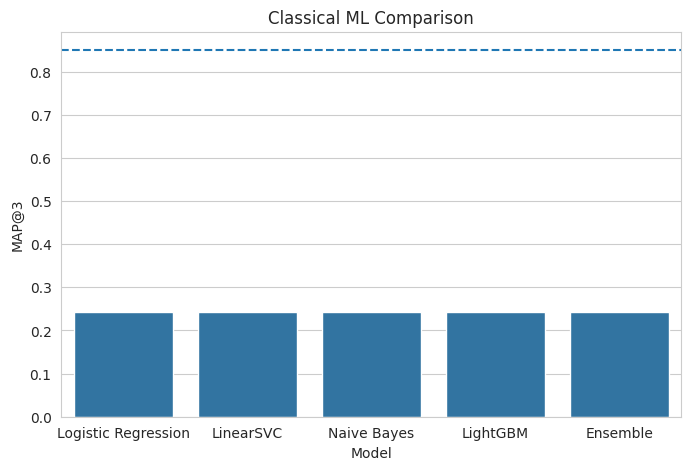

In [59]:
plt.figure(figsize=(8,5))
sns.barplot(data=results, x='Model', y='MAP@3')
plt.axhline(0.85, linestyle='--')
plt.title("Classical ML Comparison")
plt.show()

In [60]:
import os
from kaggle_secrets import UserSecretsClient

# API key Kaggle Secret se lo
secrets = UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login(key=os.environ["WANDB_API_KEY"], relogin=True)

# W&B run start karo
wandb.init(
    project="23f2005181-t22026",
    name="classical-ml",
    config={
        "vectorizer": "TF-IDF",
        "train_size": len(train_data),
        "val_size": len(val_data)
    }
)

wandb.log({
    "logistic_map3": score,
    "linear_svc_mp@3":score_svc,
    "naive_bayes_map3": score_nb,
    "lgbm_map3": score_lgbm,
    "ensemble_map3": score_ensemble
})
wandb.finish()
print(" W&B done!")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


ensemble_map3,▁
lgbm_map3,▁
linear_svc_mp@3,▁
logistic_map3,▁
naive_bayes_map3,▁
ensemble_map3,0.24298
lgbm_map3,0.24174
linear_svc_mp@3,0.24298
logistic_map3,0.24298
naive_bayes_map3,0.24298


 W&B done!


In [ ]:
test_rows = []
for _, row in test_df.iterrows():
    for option in ['A', 'B', 'C', 'D', 'E']:
        test_rows.append({
            'text': clean_text(f"Question: {row['prompt']} Answer: {row[option]}"),
           
            'question_id': row['id'],
            'option': option
        })

test_expanded = pd.DataFrame(test_rows)
print('Test expanded shape:', test_expanded.shape)  # 2500 rows honi chahiye

# Step 2 — Vectorize (fit nahi, sirf transform)
X_test_vec = vectorizer.transform(test_expanded['text'])

# Step 3 — Probability lo (class 1 = correct hone ki probability)
test_expanded['prob'] = lr_model.predict_proba(X_test_vec)[:, 1]

# Step 4 — Har question ke liye top 3 rank karo
final_predictions = []
for qid, group in test_expanded.groupby('question_id'):
    ranked = group.sort_values('prob', ascending=False)['option'].tolist()
    final_predictions.append(' '.join(ranked[:3]))

# Step 5 — Submission banao
submission = pd.DataFrame({
    'ID': test_df['id'],
    'Prediction': final_predictions
})

# Format check
assert len(submission) == 500, '500 rows honi chahiye!'
assert all(len(p.split()) == 3 for p in submission['Prediction']), 'Har row mein 3 options chahiye!'
print('Format check passed!')
print(submission.head(10))

submission.to_csv('submission.csv', index=False)
print('submission.csv ready!')

# Deep Learning Models

# *Pytorch Imports*

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
import wandb
import os
from kaggle_secrets import UserSecretsClient

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

In [ ]:
# import requests
# import time

# # Groq API key
# groq_key = secrets.get_secret("GROQ_API_KEY")

# def ask_groq_mcq(prompt, opts, retries=3):
#     opt_text = "\n".join([f"{k}: {v}" for k, v in opts.items()])

#     message = f"""You are an expert MCQ solver. Analyze the question carefully and rank all options.

# Question: {prompt}

# Options:
# {opt_text}

# Instructions:
# - Read each option carefully
# - The correct answer is usually the most complete and accurate one
# - Return ONLY 3 letters separated by spaces, best first
# - Example: B D A

# Answer:"""
#     for attempt in range(retries):
#         try:
#             response = requests.post(
#                 "https://api.groq.com/openai/v1/chat/completions",
#                 headers={
#                     "Authorization": f"Bearer {groq_key}",
#                     "Content-Type" : "application/json"
#                 },
#                 json={
#                     "model"      : "llama-3.3-70b-versatile",
#                     "messages"   : [{"role": "user", "content": message}],
#                     "max_tokens" : 15,
#                     "temperature": 0.0
#                 },
#                 timeout=30
#             )

#             if response.status_code == 429:
#                 # Rate limit — thoda ruko
#                 time.sleep(5)
#                 continue

#             raw = response.json()['choices'][0]['message']['content'].strip()

#             # Sirf valid options parse karo
#             tokens = [t.upper() for t in raw.split() if t.upper() in ['A','B','C','D','E']]

#             # Duplicates hatao
#             seen = []
#             for t in tokens:
#                 if t not in seen:
#                     seen.append(t)
#             tokens = seen

#             # 3 se kam aaye toh baaki options add karo
#             for opt in ['A','B','C','D','E']:
#                 if opt not in tokens:
#                     tokens.append(opt)

#             return tokens[:3]

#         except Exception as e:
#             print(f"  Retry {attempt+1}: {e}")
#             time.sleep(2)

#     # Fallback — longest option
#     lengths = {o: len(str(opts[o])) for o in opts}
#     return sorted(lengths, key=lengths.get, reverse=True)[:3]


# # ── Validation  test 
# print("Testing on 50 validation samples...")
# sample_val  = train_df.sample(50, random_state=seed).reset_index(drop=True)
# preds_val   = []
# actuals_val = []

# for i, row in sample_val.iterrows():
#     opts = {o: row[o] for o in ['A','B','C','D','E']}
#     pred = ask_groq_mcq(row['prompt'], opts)
#     preds_val.append(pred)
#     actuals_val.append(row['answer'])
#     time.sleep(0.5)  # Rate limit
# val_score_groq = map_at_3(actuals_val, preds_val)
# print(f"Groq Validation MAP@3 (50 samples): {val_score_groq:.4f}")

In [ ]:
# import requests
# import time

# groq_key = secrets.get_secret("GROQ_API_KEY")

# # Pehle ek single test karo
# test_response = requests.post(
#     "https://api.groq.com/openai/v1/chat/completions",
#     headers={
#         "Authorization": f"Bearer {groq_key}",
#         "Content-Type" : "application/json"
#     },
#     json={
#         "model"    : "llama-3.3-70b-versatile",
#         "messages" : [{"role": "user", "content": "Say hello"}],
#         "max_tokens": 10
#     },
#     timeout=30
# )

# print("Status code:", test_response.status_code)
# print("Response:", test_response.json())

In [ ]:
# wandb.init(
#     project = '23f2005181-t22026',
#     name    = 'groq-llama70b-zeroshot',
#     config  = {
#         'model'      : 'llama-3.3-70b-versatile',
#         'approach'   : 'zero-shot MCQ ranking',
#         'test_size'  : 500,
#         'temperature': 0.0
#     }
# )
# wandb.log({'groq_val_map3': val_score_groq})
# wandb.finish()
# print('✅ W&B done!')

In [ ]:
# # ── Full test set — 500 questions ──
# print("Running on full test set (500 questions)...")

# lookup = train_df.drop_duplicates('prompt').set_index('prompt')['answer'].to_dict()

# final_predictions = []
# failed = 0

# for i, row in test_df.iterrows():
#     prompt = row['prompt']

#     # Lookup pehle check karo
#     if prompt in lookup:
#         known = lookup[prompt]
#         rest  = [o for o in ['A','B','C','D','E'] if o != known]
#         final_predictions.append(known + ' ' + ' '.join(rest[:2]))
#         continue

#     # Groq se predict karo
#     opts = {o: row[o] for o in ['A','B','C','D','E']}
#     pred = ask_groq_mcq(prompt, opts)
#     final_predictions.append(' '.join(pred))

#     # Progress print karo
#     if (i+1) % 50 == 0:
#         print(f"  {i+1}/500 done...")

#     time.sleep(0.5)  # Rate limit handle

# print(f"\n✅ Done! Failed requests: {failed}")

# # ── Submission ──
# submission = pd.DataFrame({
#     'ID'         : test_df['id'],
#     'Prediction' : final_predictions
# })

# assert len(submission) == 500
# assert all(len(p.split()) == 3 for p in submission['Prediction'])
# print('✅ Format check passed!')
# print(submission.head(10))

# submission.to_csv('submission.csv', index=False)
# print(' Submit karo Kaggle pe!')

In [ ]:
# from sentence_transformers import CrossEncoder

# # Cross encoder — question + option ek saath judge karta hai
# cross_encoder = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')

# lookup = train_df.drop_duplicates('prompt').set_index('prompt')['answer'].to_dict()

# final_predictions = []

# for _, row in test_df.iterrows():
#     prompt = str(row['prompt'])  # original text
    
#     if prompt in lookup:
#         known = lookup[prompt]
#         rest  = [o for o in ['A','B','C','D','E'] if o != known]
#         final_predictions.append(known + ' ' + ' '.join(rest[:2]))
#         continue
    
#     # Cross encoder — question + option pair score karta hai
#     pairs  = [[prompt, str(row[o])] for o in ['A','B','C','D','E']]
#     scores = cross_encoder.predict(pairs)
    
#     ranked = sorted(
#         zip(['A','B','C','D','E'], scores),
#         key=lambda x: x[1],
#         reverse=True
#     )
#     top3 = [o for o, _ in ranked[:3]]
#     final_predictions.append(' '.join(top3))

# submission = pd.DataFrame({
#     'ID'        : test_df['id'],
#     'Prediction': final_predictions
# })

# assert len(submission) == 500
# assert all(len(p.split()) == 3 for p in submission['Prediction'])
# print('Done!')
# submission.to_csv('submission.csv', index=False)
# print('Submit!')